# Echo benchmark: mpstab vs Pauli propagation

A kicked Ising Floquet evolution $U$ (Clifford $ZZ$ couplings, magic $R_X$/$R_Z$
kicks) followed by $U^\dagger$ is the identity, so
$\langle Z_{n/2}\rangle = 1$ **exactly, at any width and depth**. Neither
simulator can tell: mpstab evolves the MPS through $U$'s entanglement and back
out, and Pauli propagation grows $U$'s Pauli terms and has to cancel them again.
Both truncations (bond dimension $\chi$, coefficient threshold) show up as
error.

**Launch** from the repository root:

```bash
uv run --with juliacall --with pandas --with jupyterlab jupyter lab examples/notebooks/benchmarks/
```

The PauliPropagation.jl cells download Julia and the package on first use (a
few minutes); everything else needs only mpstab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import frameworks as fw


N = 64
STEPS = [2, 4, 6, 8, 10, 12]
THETA_H, THETA_Z = 0.7, 0.3       # the magic kicks
CHI = [64, 128]
PP_THRESHOLDS = [1e-3, 1e-4, 1e-5]
TIMEOUT = 120                     # seconds per Pauli propagation run

[Qibo 0.3.6|INFO|2026-11-17 09:56:14]: Using numpy backend on /CPU:0


In [2]:
def echo_circuit(n, steps):
    forward = fw.kicked_ising(n, steps, theta_h=THETA_H, theta_z=THETA_Z)
    return forward + forward.invert()


observable = fw.local_z(N, (N // 2,))
rows = []
for steps in STEPS:
    circuit = echo_circuit(N, steps)
    for chi in CHI:
        r = fw.run_mpstab(circuit, observable, max_bond=chi)
        rows.append(dict(method=f"mpstab $\\chi$={chi}", steps=steps,
                         error=abs(r["value"] - 1), time=r["time"]))
    for threshold in PP_THRESHOLDS:
        r = fw.run_pp_isolated(circuit, [], observable, timeout=TIMEOUT,
                               warmup_gates=len(circuit.queue) // (2 * steps),
                               min_abs_coeff=threshold)
        rows.append(dict(method=f"PauliPropagation {threshold:g}", steps=steps,
                         error=np.nan if r is None else abs(r["value"] - 1),
                         time=np.nan if r is None else r["time"]))
    print(f"T={steps} done")
results = pd.DataFrame(rows)

T=2 done


T=4 done


/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


T=6 done


T=8 done


T=10 done


T=12 done


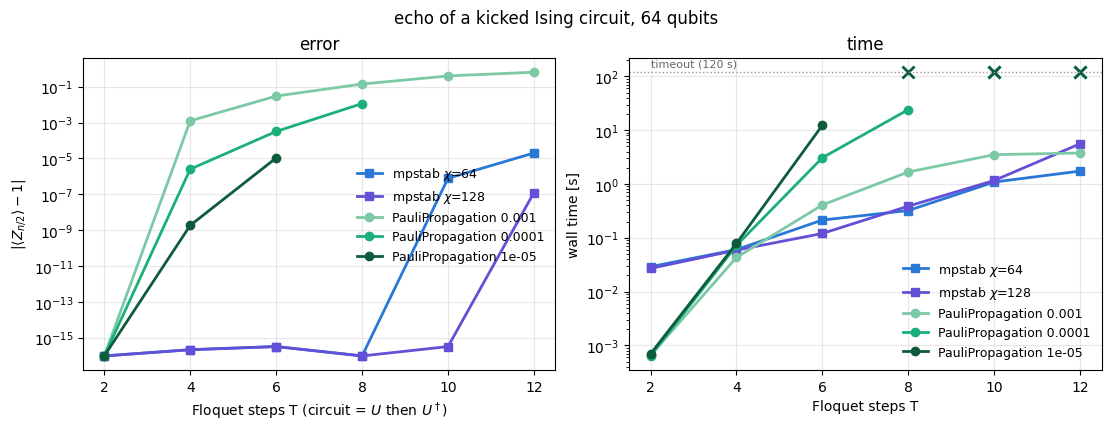

In [3]:
colors = {f"mpstab $\\chi$={c}": col for c, col in zip(CHI, ["#2a78d6", "#6250d6"])}
colors.update({f"PauliPropagation {t:g}": col
               for t, col in zip(PP_THRESHOLDS, ["#7cc9a6", "#1baf7a", "#0c5c3c"])})

fig, (ax_error, ax_time) = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for method, d in results.groupby("method", sort=False):
    style = dict(color=colors[method], marker="s" if "mpstab" in method else "o",
                 linewidth=2, label=method)
    done = d.dropna()
    ax_error.plot(done.steps, done.error.clip(lower=1e-16), **style)
    ax_time.plot(done.steps, done.time, **style)
    timed_out = d[d.time.isna()]
    ax_time.plot(timed_out.steps, [TIMEOUT] * len(timed_out), "x",
                 color=colors[method], markersize=9, mew=2)
ax_time.axhline(TIMEOUT, color="0.6", linestyle=":", linewidth=1)
ax_time.annotate(f"timeout ({TIMEOUT} s)", (STEPS[0], TIMEOUT), xytext=(0, 4),
                 textcoords="offset points", fontsize=8, color="0.4")
ax_error.set(yscale="log", xlabel="Floquet steps T (circuit = $U$ then $U^\\dagger$)",
             ylabel="$|\\langle Z_{n/2}\\rangle - 1|$", title="error")
ax_time.set(yscale="log", xlabel="Floquet steps T", ylabel="wall time [s]", title="time")
ax_error.legend(frameon=False, fontsize=9, loc="center right")
ax_time.legend(frameon=False, fontsize=9, loc="lower right")
for ax in (ax_error, ax_time):
    ax.grid(alpha=0.3)
fig.suptitle(f"echo of a kicked Ising circuit, {N} qubits");

In [4]:
results.pivot(index="steps", columns="method", values=["error", "time"])

error                                                \
method PauliPropagation 0.0001 PauliPropagation 0.001 PauliPropagation 1e-05   
steps                                                                          
2                     0.000000               0.000000           0.000000e+00   
4                     0.000003               0.001256           1.880356e-09   
6                     0.000320               0.029966           1.070823e-05   
8                     0.011437               0.140621                    NaN   
10                         NaN               0.397063                    NaN   
12                         NaN               0.641702                    NaN   

                                                             time  \
method mpstab $\chi$=128 mpstab $\chi$=64 PauliPropagation 0.0001   
steps                                                               
2           0.000000e+00     0.000000e+00                0.000638   
4           2.220446e-16     2.220446e-16                0.072157   
6           3.330669e-16     3.330669e-16                3.083810   
8           0.000000e+00     0.000000e+00               24.199268   
10          3.330669e-16     7.887690e-07                     NaN   
12          1.268659e-07     2.026276e-05                     NaN   

                                                                        \
method PauliPropagation 0.001 PauliPropagation 1e-05 mpstab $\chi$=128   
steps                                                                    
2                    0.000654               0.000695          0.027001   
4                    0.043245               0.078693          0.058977   
6                    0.408858              12.374697          0.120580   
8                    1.676191                    NaN          0.388144   
10                   3.512329                    NaN          1.165583   
12                   3.781336                    NaN          5.615291   

                         
method mpstab $\chi$=64  
steps                    
2              0.029077  
4              0.060486  
6              0.214061  
8              0.321941  
10             1.089443  
12             1.741837